# RFM và phân khúc giá trị khách hàng — Online Retail II
## Phần A: RFM trên toàn bộ dữ liệu. Phần B: RFM theo từng tuần

**Câu hỏi kinh doanh:** Nên ưu tiên khách hàng nào cho hoạt động giữ chân hoặc khuyến mãi để tăng biên lợi nhuận kỳ vọng trong tương lai mà không giảm giá quá mức?

**Đầu vào:** `clean_transactions.csv` do `00_data_cleaning.ipynb` tạo ra.

**Notebook này không dùng cutoff cố định, không dùng cửa sổ quan sát và không có nhãn tương lai.**

| | Phần A: toàn bộ dữ liệu | Phần B: theo từng tuần |
|---|---|---|
| **Cách tính** | R, F, M trên **toàn bộ lịch sử** của mỗi khách. R tính đến ngày sau giao dịch cuối cùng của dữ liệu | Mỗi thứ Hai là một mốc. R, F, M **tính đến mốc đó**, và thêm F, M **chỉ của riêng tuần đó** |
| **Một dòng là** | Một khách | Một khách tại một tuần |
| **Dùng để** | Hồ sơ nhóm hiện tại, Pareto, cohort | Xem từng khách đổi nhóm như thế nào theo thời gian |Ư

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

clean = pd.read_csv("clean_transactions.csv", parse_dates=["InvoiceDate"],
                    usecols=["Invoice", "InvoiceDate", "Revenue", "CustomerID", "is_return"], dtype={"Invoice": str})
clean = clean.dropna(subset=["CustomerID"]).astype({"CustomerID": int})
first_seen = clean.groupby("CustomerID")["InvoiceDate"].min()

DATA_START = clean["InvoiceDate"].min().normalize()
END = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)   # the day after the last transaction
print(f"{len(clean):,} rows | {clean['CustomerID'].nunique():,} customers | {DATA_START.date()} to {END.date()} (exclusive)")

SEGMENTS = ["Champions", "VIP at risk", "Loyal", "Developing", "One-time recent", "Cooling", "Lapsed", "Dormant"]
T = {"recency_active": 90, "recency_lapsed": 180, "recency_dormant": 365, "freq_repeat": 2, "freq_loyal": 4}

def assign_segment(r, monetary_high):
    high_value = r["monetary"] >= monetary_high
    active = r["recency_days"] <= T["recency_active"]
    conditions = [
        high_value & active,
        high_value,
        active & (r["frequency"] >= T["freq_loyal"]),
        active & (r["frequency"] >= T["freq_repeat"]),
        active,
        r["recency_days"] <= T["recency_lapsed"],
        r["recency_days"] <= T["recency_dormant"],
    ]
    seg = np.select(conditions, SEGMENTS[:-1], default=SEGMENTS[-1])
    return pd.Categorical(seg, categories=SEGMENTS, ordered=True)

794,165 rows | 5,875 customers | 2009-12-01 to 2011-12-10 (exclusive)


# Phần A. RFM trên toàn bộ dữ liệu

## 8. Đặc trưng RFM

### 8.1 Định nghĩa

| Đặc trưng | Định nghĩa | Lý do |
|---|---|---|
| `recency_days` (R) | Số ngày từ lần **mua** cuối đến ngày sau giao dịch cuối của dữ liệu | Hóa đơn trả hàng không tính là hoạt động mua |
| `frequency` (F) | Số hóa đơn bán khác nhau trong toàn bộ lịch sử | Khớp với mốc 1 / 2-3 / 4+ ở mục 6.13 |
| `monetary` (M) | Doanh số bán trừ hàng trả trong toàn bộ lịch sử, sàn ở 0 | Hàng trả làm hao hụt giá trị thật của khách |
| `purchase_days` | Số ngày mua khác nhau | Đối chiếu với F (khách bán buôn có thể xuất nhiều hóa đơn trong một ngày) |
| `avg_order_value` | Doanh số bán / F | Phân biệt khách đơn lớn với khách đơn nhỏ |
| `return_rate` | Giá trị hàng trả / doanh số bán | Hàng trả làm hao hụt biên lợi nhuận |
| `tenure_days` | Số ngày từ lần đầu xuất hiện đến ngày tính | Khách lâu năm hay khách mới |
| `avg_gap_days` | Số ngày trung bình giữa hai ngày mua liên tiếp (rỗng nếu chỉ mua một ngày) | Nhịp mua riêng của từng khách |
| `recency_gap_ratio` | `recency_days` / `avg_gap_days` | Khách có nhịp 30 ngày mà đã 80 ngày không mua đáng lo hơn khách có nhịp 150 ngày. Tỷ số > 1 nghĩa là đã im lặng lâu hơn nhịp thường lệ |
| `frequency_90d`, `monetary_90d` | F và M chỉ tính 90 ngày cuối | Hoạt động gần đây, nhạy hơn số liệu toàn lịch sử |
| `monetary_90d_share` | `monetary_90d` / `monetary` | Khách đang tăng hay giảm hoạt động so với mức toàn lịch sử |

Các cột nhịp mua và 90 ngày **không dùng để phân nhóm**, chỉ để mô tả khách chi tiết hơn.

**Lưu ý:** vì F và M cộng dồn toàn lịch sử nên chúng chỉ tăng theo thời gian. Khách có mặt từ 2009-12 có nhiều thời gian để tích lũy hơn khách mới, nên F và M ở phần A phản ánh một phần độ dài lịch sử của khách.

In [3]:
def build_rfm(rows, ref_date):
    sales = rows[~rows["is_return"]]
    returns = rows[rows["is_return"]]
    g = sales.groupby("CustomerID")

    rfm = pd.DataFrame({
        "recency_days": (ref_date - g["InvoiceDate"].max()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "purchase_days": g["InvoiceDate"].apply(lambda d: d.dt.normalize().nunique()),
        "gross_sales": g["Revenue"].sum(),
    })
    rfm["return_value"] = -returns.groupby("CustomerID")["Revenue"].sum()
    rfm["return_value"] = rfm["return_value"].fillna(0)
    rfm["monetary"] = (rfm["gross_sales"] - rfm["return_value"]).clip(lower=0)
    rfm["avg_order_value"] = rfm["gross_sales"] / rfm["frequency"]
    rfm["return_rate"] = rfm["return_value"] / rfm["gross_sales"]
    rfm["tenure_days"] = (ref_date - first_seen.reindex(rfm.index)).dt.days

    # Purchase rhythm: mean gap between distinct purchase days, and how long the customer has been silent relative to it
    days = sales.assign(day=sales["InvoiceDate"].dt.normalize()).groupby("CustomerID")["day"]
    rfm["avg_gap_days"] = (days.max() - days.min()).dt.days / (rfm["purchase_days"] - 1).replace(0, np.nan)
    rfm["recency_gap_ratio"] = rfm["recency_days"] / rfm["avg_gap_days"]

    # Short window: last 90 days before ref_date
    last90 = ref_date - pd.Timedelta(days=90)
    g90 = sales[sales["InvoiceDate"] >= last90].groupby("CustomerID")
    ret90 = returns[returns["InvoiceDate"] >= last90].groupby("CustomerID")["Revenue"].sum()
    gross90 = g90["Revenue"].sum()
    rfm["frequency_90d"] = g90["Invoice"].nunique().reindex(rfm.index).fillna(0).astype(int)
    rfm["monetary_90d"] = (gross90 + ret90.reindex(gross90.index).fillna(0)).clip(lower=0).reindex(rfm.index).fillna(0)
    rfm["monetary_90d_share"] = rfm["monetary_90d"] / rfm["monetary"].replace(0, np.nan)
    return rfm.reset_index()

rfm = build_rfm(clean, END)
assert rfm[["recency_days", "frequency", "monetary"]].notna().all().all()
print(f"{len(rfm):,} customers with at least one sale")

rfm[["recency_days", "frequency", "purchase_days", "monetary", "avg_order_value", "return_rate", "tenure_days",
     "avg_gap_days", "recency_gap_ratio", "frequency_90d", "monetary_90d", "monetary_90d_share"]] \
    .describe(percentiles=[.25, .5, .75, .9, .95, .99])

5,852 customers with at least one sale


,recency_days,frequency,purchase_days,monetary,avg_order_value,return_rate,tenure_days,avg_gap_days,recency_gap_ratio,frequency_90d,monetary_90d,monetary_90d_share
count,"5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","4,179.00","4,179.00","5,852.00","5,852.00","5,833.00"
mean,199.73,6.25,5.62,"2,795.90",384.40,0.02,475.66,111.48,3.75,1.12,534.36,0.22
std,208.52,12.75,9.92,"13,825.20","1,254.73",0.10,224.35,102.34,22.37,2.51,"3,020.71",0.32
min,0.00,1.00,1.00,0.00,2.95,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,25.00,1.00,1.00,330.94,176.15,0.00,313.00,44.00,0.22,0.00,0.00,0.00
50%,95.00,3.00,3.00,840.25,277.87,0.00,532.00,80.00,0.64,0.00,0.00,0.00
75%,379.00,7.00,6.00,"2,172.03",410.56,0.01,670.00,142.00,2.14,1.00,474.06,0.30
90%,530.00,13.00,12.00,"5,224.45",624.03,0.05,731.00,238.20,6.23,3.00,"1,131.14",1.00
95%,623.00,20.00,18.45,"8,899.83",871.21,0.10,736.00,348.00,12.79,4.00,"1,849.46",1.00
99%,726.00,46.00,39.00,"26,490.31","1,907.11",0.39,738.00,513.22,37.34,9.00,"4,813.24",1.00


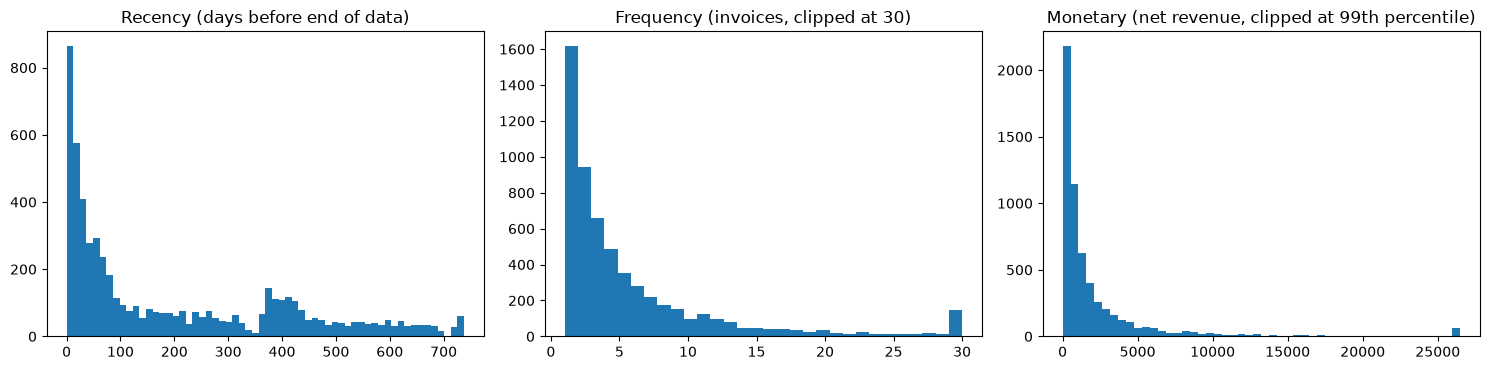

Share of customers with F != purchase_days: 20.8%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(rfm["recency_days"], bins=60, color="tab:blue")
axes[1].hist(rfm["frequency"].clip(upper=30), bins=30, color="tab:blue")
axes[2].hist(rfm["monetary"].clip(upper=rfm["monetary"].quantile(.99)), bins=50, color="tab:blue")
axes[0].set_title("Recency (days before end of data)")
axes[1].set_title("Frequency (invoices, clipped at 30)")
axes[2].set_title("Monetary (net revenue, clipped at 99th percentile)")
plt.tight_layout(); plt.show()

print(f"Share of customers with F != purchase_days: {(rfm['frequency'] != rfm['purchase_days']).mean():.1%}")

**Ý nghĩa của "Share of customers with F != purchase_days" (20.8%):** đây là tỷ lệ khách có số hóa đơn (F) lớn hơn số ngày mua khác nhau (`purchase_days`), tức là khách có **nhiều hóa đơn trong cùng một ngày**.

* F đếm số hóa đơn; `purchase_days` đếm số ngày khác nhau có mua. Hai số bằng nhau khi mỗi ngày khách chỉ có một hóa đơn.
* Ví dụ: khách mua vào thứ Hai và có hai hóa đơn (một cho hàng khô, một cho hàng đông lạnh) thì F tăng 2 nhưng chỉ có 1 ngày mua.
* Khách bán buôn thường tách đơn như vậy (theo nhà kho hoặc theo loại hàng), nên F của họ có thể cao hơn số lần quay lại thật sự. Khách có F = 4 chưa chắc đã quay lại 4 lần.
* Notebook vẫn dùng **F theo hóa đơn** trong luật phân nhóm, để khớp với các mốc 1 / 2-3 / 4+ ở mục 6.13. Cột `purchase_days` được giữ lại để đối chiếu. Nếu muốn F phản ánh số lần quay lại, có thể thay F bằng `purchase_days` trong luật; một số khách Loyal khi đó sẽ xuống Developing.

### 8.2 Đặt ngưỡng

Mỗi ngưỡng có một nguồn bằng chứng:
* **R:** mốc 90 ngày và 180 ngày từ mục 6.9 (71% khách có trung vị khoảng cách mua ≤ 90 ngày, 93% ≤ 180 ngày). Quá 90 ngày là khách bắt đầu "nguội", quá 180 ngày là đã vắng lâu. Mốc **365 ngày** (một năm không mua) tách khách quá 180 ngày thành hai nhóm: Lapsed (181-365) và Dormant (> 365).
* **F:** mốc 1 / 2-3 / 4+ hóa đơn từ mục 6.13.
* **M:** đường cong tập trung doanh thu (Pareto). Ngưỡng "giá trị cao" là mức doanh thu của top 10% khách.

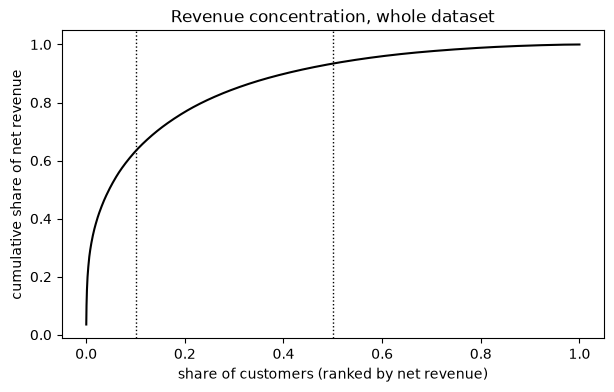

monetary_high (top 10%) = 5,224.45


,monetary_threshold,share_of_revenue
customers,,
top 1%,"26,679.24",0.31
top 5%,"8,945.53",0.51
top 10%,"5,250.78",0.63
top 20%,"2,835.36",0.77
top 30%,"1,743.15",0.85
top 50%,840.25,0.93


In [5]:
m = rfm["monetary"].sort_values(ascending=False).reset_index(drop=True)
cum_share = m.cumsum() / m.sum()
qs = (.01, .05, .10, .20, .30, .50)
pareto = pd.DataFrame({
    "monetary_threshold": [m.iloc[int(len(m) * q) - 1] for q in qs],
    "share_of_revenue": [cum_share.iloc[int(len(m) * q) - 1] for q in qs],
}, index=pd.Index(["top 1%", "top 5%", "top 10%", "top 20%", "top 30%", "top 50%"], name="customers"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(m) + 1) / len(m), cum_share, color="black")
for q in (.1, .5):
    ax.axvline(q, color="k", ls=":", lw=1)
ax.set_xlabel("share of customers (ranked by net revenue)"); ax.set_ylabel("cumulative share of net revenue")
ax.set_title("Revenue concentration, whole dataset"); plt.show()

MONETARY_HIGH = rfm["monetary"].quantile(.90)
print(f"monetary_high (top 10%) = {MONETARY_HIGH:,.2f}")
pareto

### 8.3 Luật phân nhóm

Các điều kiện được xét **theo thứ tự**: khách rơi vào điều kiện đầu tiên đúng. Nhờ vậy các nhóm loại trừ nhau và phủ hết mọi khách (8 nhóm).

| # | Nhóm | Điều kiện | Ý nghĩa |
|---|---|---|---|
| 1 | Champions | M ≥ top 10% **và** R ≤ 90 | Giá trị cao nhất, đang hoạt động |
| 2 | VIP at risk | M ≥ top 10% **và** R > 90 | Từng giá trị cao nhưng đã lâu không mua |
| 3 | Loyal | R ≤ 90 **và** F ≥ 4 | Mua đều, giá trị vừa |
| 4 | Developing | R ≤ 90 **và** F = 2-3 | Đã mua lại, chưa thành thói quen |
| 5 | One-time recent | R ≤ 90 **và** F = 1 | Mới mua một lần gần đây |
| 6 | Cooling | 90 < R ≤ 180 | Đang nguội |
| 7 | Lapsed | 180 < R ≤ 365 | Đã vắng lâu nhưng còn cơ hội kéo lại |
| 8 | Dormant | R > 365 | Gần như đã rời đi |

In [6]:
rfm["segment"] = assign_segment(rfm, MONETARY_HIGH)
assert rfm["segment"].notna().all()

rfm["segment"].value_counts().reindex(SEGMENTS).rename("customers").to_frame()

,customers
segment,
Champions,515
VIP at risk,71
Loyal,1345
Developing,658
One-time recent,367
Cooling,555
Lapsed,777
Dormant,1564


### 8.4 Hồ sơ nhóm

Với mỗi nhóm: quy mô, đặc điểm (R, F, M, trả hàng, nhịp mua) và phần đóng góp vào doanh thu.

In [7]:
profile = rfm.groupby("segment", observed=False).agg(
    customers=("CustomerID", "size"),
    median_recency=("recency_days", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median"),
    mean_monetary=("monetary", "mean"),
    median_return_rate=("return_rate", "median"),
    median_avg_gap_days=("avg_gap_days", "median"),
    median_monetary_90d=("monetary_90d", "median"),
    total_monetary=("monetary", "sum"),
)
profile.insert(1, "share_customers", profile["customers"] / profile["customers"].sum())
profile["share_revenue"] = profile.pop("total_monetary") / rfm["monetary"].sum()
profile

,customers,share_customers,median_recency,median_frequency,median_monetary,mean_monetary,median_return_rate,median_avg_gap_days,median_monetary_90d,share_revenue
segment,,,,,,,,,,
Champions,515,0.09,11.00,20.00,"8,945.53","18,449.48",0.01,37.53,"1,551.72",0.58
VIP at risk,71,0.01,184.00,13.00,"8,550.92","11,978.52",0.01,43.02,0.00,0.05
Loyal,1345,0.23,24.00,7.00,"2,070.71","2,294.74",0.00,79.44,474.02,0.19
Developing,658,0.11,29.00,2.00,663.66,805.98,0.00,164.75,347.52,0.03
One-time recent,367,0.06,44.00,1.00,256.32,368.84,0.00,NaN,256.32,0.01
Cooling,555,0.09,131.00,3.00,868.77,"1,241.88",0.00,106.70,0.00,0.04
Lapsed,777,0.13,260.00,2.00,566.13,870.61,0.00,107.67,0.00,0.04
Dormant,1564,0.27,468.00,1.00,338.56,570.21,0.00,74.50,0.00,0.05


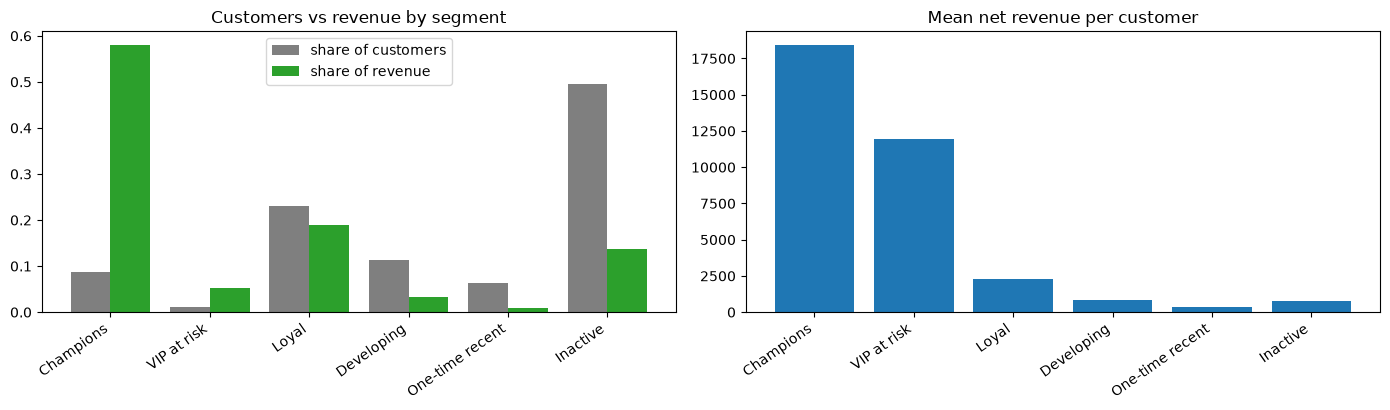

In [8]:
# Cooling, Lapsed and Dormant are merged into one "Inactive" group; the other five segments stay as they are
MERGED = SEGMENTS[:5] + ["Inactive"]
seg_merged = rfm["segment"].astype(str).where(rfm["segment"].isin(SEGMENTS[:5]), "Inactive")
prof_m = rfm.groupby(seg_merged).agg(customers=("CustomerID", "size"), mean_monetary=("monetary", "mean"),
                                     total_monetary=("monetary", "sum")).reindex(MERGED)
prof_m["share_customers"] = prof_m["customers"] / prof_m["customers"].sum()
prof_m["share_revenue"] = prof_m["total_monetary"] / prof_m["total_monetary"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(MERGED))
axes[0].bar(x - .2, prof_m["share_customers"], width=.4, color="tab:gray", label="share of customers")
axes[0].bar(x + .2, prof_m["share_revenue"], width=.4, color="tab:green", label="share of revenue")
axes[0].set_title("Customers vs revenue by segment")
axes[1].bar(x, prof_m["mean_monetary"], color="tab:blue")
axes[1].set_title("Mean net revenue per customer")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(MERGED, rotation=35, ha="right")
axes[0].legend()
plt.tight_layout(); plt.show()

### 8.5 Cohort view: giữ chân theo tháng mua đầu tiên

Mỗi cohort là nhóm khách có lần mua đầu tiên trong cùng một tháng. Ô (cohort, k) là tỷ lệ khách của cohort đó có mua trong tháng thứ k sau tháng đầu tiên.

**Lưu ý:**
* Dữ liệu bắt đầu từ 2009-12, nên cohort 2009-12 gồm cả khách đã mua từ trước đó, và tỷ lệ giữ chân của cohort này cao hơn thực tế của một cohort khách mới.
* Tháng 2011-12 chỉ có dữ liệu đến ngày 9, nên ô cuối cùng của mỗi hàng (đường chéo cuối của ma trận) thấp hơn thực tế.

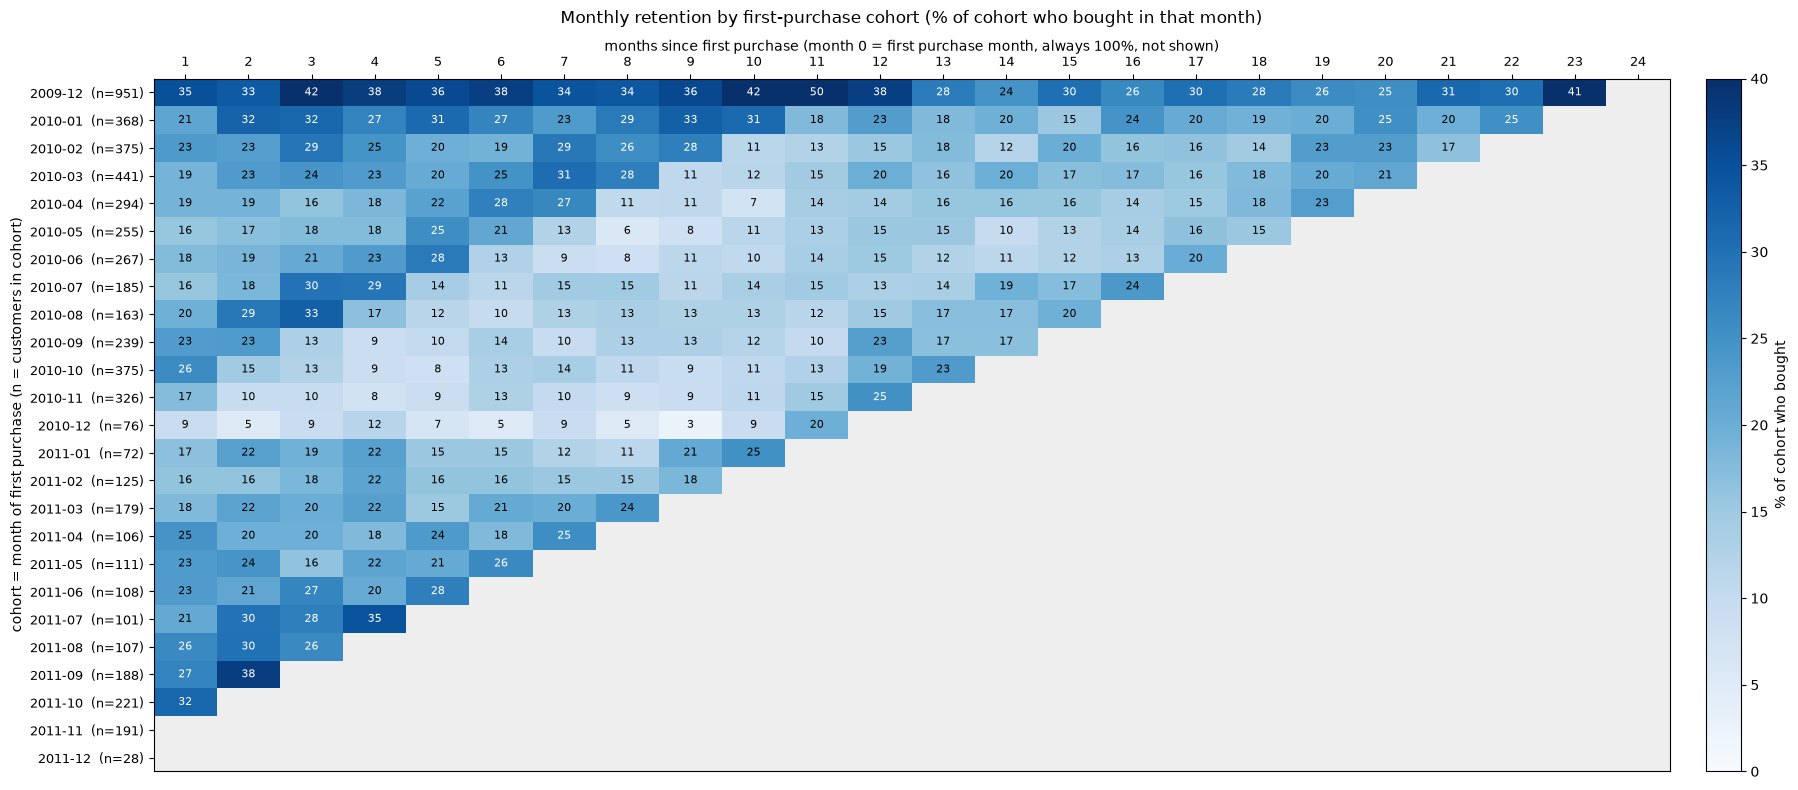

In [9]:
active = clean[~clean["is_return"]].assign(month=lambda d: d["InvoiceDate"].dt.to_period("M"))[["CustomerID", "month"]].drop_duplicates()
active["cohort"] = active.groupby("CustomerID")["month"].transform("min")
active["months_since_first"] = (active["month"] - active["cohort"]).apply(lambda p: p.n)

counts = active.pivot_table(index="cohort", columns="months_since_first", values="CustomerID", aggfunc="nunique")
retention = counts.div(counts[0], axis=0)

# Heatmap: every month after the first purchase, % written in every cell.
# 2011-12 is cut at day 9, so cells that fall in that calendar month are left blank (grey) instead of showing a false low value.
MAX_K, last_full = int(retention.columns.max()), pd.Period("2011-11", "M")
heat = retention.loc[:, 1:MAX_K].copy()
for c in heat.index:
    for k in heat.columns:
        if c + int(k) > last_full:
            heat.loc[c, k] = np.nan
data = np.ma.masked_invalid(heat.values * 100)

fig, ax = plt.subplots(figsize=(20, 8))
cmap = plt.cm.Blues.copy(); cmap.set_bad("#eeeeee")
im = ax.imshow(data, aspect="auto", cmap=cmap, vmin=0, vmax=40)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v * 100:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v * 100 > 25 else "black")
ax.set_yticks(range(len(heat))); ax.set_yticklabels([f"{c}  (n={int(n):,})" for c, n in counts[0].items()], fontsize=9)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, fontsize=9)
ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
ax.set_xlabel("months since first purchase (month 0 = first purchase month, always 100%, not shown)")
ax.set_ylabel("cohort = month of first purchase (n = customers in cohort)")
ax.set_title("Monthly retention by first-purchase cohort (% of cohort who bought in that month)", pad=40)
fig.colorbar(im, ax=ax, label="% of cohort who bought", pad=.02)
plt.tight_layout(); plt.show()

**Cách đọc heatmap giữ chân theo cohort:**

* **Mỗi hàng** là một cohort: nhóm khách có lần mua đầu tiên trong cùng một tháng (n = số khách của cohort, là mẫu số).
* **Mỗi cột** là số tháng kể từ tháng mua đầu, hiện đủ mọi tháng có dữ liệu. Cột 1 là tháng ngay sau tháng mua đầu. Tháng 0 luôn là 100% nên không vẽ.
* **Mỗi ô** ghi % khách của cohort đó có mua đúng trong tháng đó. Ô càng đậm thì tỷ lệ càng cao.
* **Không cộng dồn:** mỗi ô độc lập với ô bên cạnh. Khách nghỉ vài tháng rồi quay lại vẫn được tính ở tháng quay lại, nên một hàng có thể tăng trở lại (ví dụ hàng 2010-09: cột 12 là 23% trong khi các cột 9 đến 11 chỉ 10 đến 13%).
* **Ví dụ:** hàng 2010-09 (n=239), cột 1 ghi 23 nghĩa là khoảng 23% trong 239 khách (khoảng 55 người) có mua lại vào 2010-10.
* **Ô xám** là chưa có dữ liệu: tháng đó chưa xảy ra, hoặc rơi vào 2011-12 (dữ liệu chỉ đến ngày 9 nên tỷ lệ sẽ thấp giả tạo). Hai hàng cuối (2011-11, 2011-12) xám hoàn toàn vì chưa có tháng đầy đủ nào sau đó.
* **Đọc theo hàng** để xem một cohort giảm nhanh hay chậm. **Đọc theo cột** để so các cohort ở cùng độ tuổi; đây là cách so công bằng giữa các cohort.

**Nhận xét từ heatmap:**

| # | Phát hiện | Bằng chứng | Ý nghĩa |
|---|---|---|---|
| 1 | Cohort 2009-12 cao nhất nhưng không đại diện cho khách mới | 33 đến 50% ở hầu hết các tháng | Gồm cả khách đã mua từ trước đó, không dùng để so với cohort khác |
| 2 | Khách mới quay lại nhiều nhất ngay sau lần mua đầu, rồi giảm | Cột 1 và 2 cao hơn các cột giữa ở hầu hết các hàng | Hai tháng đầu là cơ hội chính để kéo khách mới mua lần hai |
| 3 | Hiệu ứng mùa vụ tạo các ô đậm theo đường chéo | 2010-08 cột 3 là 33% (tháng 11/2010); 2011-09 cột 2 là 38% (tháng 11/2011) | Các ô này đậm vì rơi vào mùa cao điểm, không phải cohort tốt hơn. So cohort phải so cùng cột và nhớ đến mùa |
| 4 | Cohort 2010-12 giữ chân yếu nhất | 3 đến 12% ở hầu hết các tháng, n=76 | Khách mới đến sau mùa cao điểm rất ít quay lại (khớp với One-time recent teo lại sau Q4 ở phần B) |
| 5 | Cohort 2011 có vẻ ổn định hơn 2010 | Hầu hết hàng 2011 ở mức 15 đến 30%; các cohort giữa 2010 (2010-05 đến 2010-11) sau tháng thứ 3 xuống khoảng 5 đến 15% | 2011 mới quan sát tối đa 10 tháng, và các tháng đầu luôn cao hơn tháng xa, nên chưa kết luận 2011 tốt hơn. So theo cột (cùng độ tuổi) để kiểm tra |

Biểu đồ thanh nằm ngay dưới heatmap là bản rút gọn của heatmap này (mỗi cohort một con số); cách đọc và giới hạn của nó ở ô chú thích riêng.

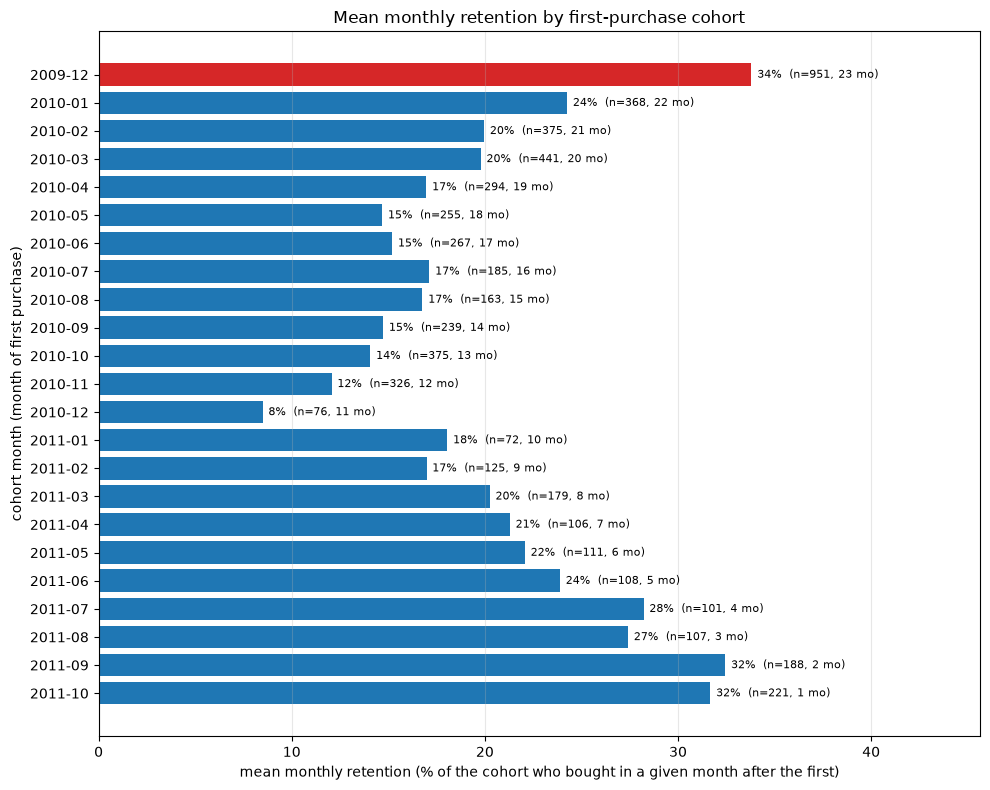

In [10]:
# Bar view: one number per cohort = mean monthly retention over the months after the first purchase that were fully observed.
# 2011-12 is cut at day 9, so that calendar month is excluded.
last_full = pd.Period("2011-11", "M")
def cohort_mean_retention(cohort, row):
    vals = [row[k] for k in row.index if k >= 1 and cohort + int(k) <= last_full and pd.notna(row[k])]
    return np.mean(vals) if vals else np.nan
cohort_ret = pd.DataFrame({
    "customers": counts[0].astype(int),
    "months_observed": [sum(1 for k in retention.columns if k >= 1 and c + int(k) <= last_full and pd.notna(retention.loc[c, k])) for c in retention.index],
    "mean_monthly_retention": [cohort_mean_retention(c, retention.loc[c]) for c in retention.index],
}).dropna()

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["tab:red" if c == pd.Period("2009-12", "M") else "tab:blue" for c in cohort_ret.index]
ax.barh(cohort_ret.index.astype(str), cohort_ret["mean_monthly_retention"] * 100, color=colors)
for y, (c, r) in enumerate(cohort_ret.iterrows()):
    ax.text(r["mean_monthly_retention"] * 100 + .3, y, f"{r['mean_monthly_retention']:.0%}  (n={int(r['customers']):,}, {int(r['months_observed'])} mo)",
            va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, cohort_ret["mean_monthly_retention"].max() * 100 * 1.35)
ax.set_xlabel("mean monthly retention (% of the cohort who bought in a given month after the first)")
ax.set_ylabel("cohort month (month of first purchase)")
ax.set_title("Mean monthly retention by first-purchase cohort")
ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

**Cách đọc biểu đồ thanh (mean monthly retention theo cohort):**

Biểu đồ này **rút gọn heatmap**: mỗi hàng của heatmap (một cohort) chỉ còn một thanh, tức một con số.

* **Trục dọc (cohort month):** tháng khách mua lần đầu. Mỗi thanh là một cohort, giống một hàng của heatmap.
* **Trục ngang (mean monthly retention):** trung bình các % trong hàng đó của heatmap, tính trên mọi tháng sau lần mua đầu mà cohort đã quan sát được. Không tính tháng 2011-12 vì dữ liệu chỉ đến ngày 9.
* **Nhãn cuối thanh** gồm ba phần: `15%` là trung bình, `n=239` là số khách của cohort (mẫu số), `14 mo` là số tháng đã dùng để tính trung bình.
* **Ví dụ:** thanh 2010-09 ghi `15% (n=239, 14 mo)`. Đó là trung bình của 14 con số ở hàng 2010-09 của heatmap (23, 23, 13, 9, 10, 14, 10, 13, 13, 12, 10, 23, 17, 17), tức khoảng 15%. Nghĩa là trong một tháng bất kỳ về sau, khoảng 15% khách của cohort này có mua.
* **Thanh đỏ** là cohort 2009-12: gồm cả khách đã mua từ trước đó nên cao hơn thực tế của khách mới.

**Cách dùng và giới hạn:**

| # | Lưu ý | Lý do |
|---|---|---|
| 1 | Thanh dài hơn nghĩa là cohort quay lại mua thường xuyên hơn **nhìn chung** | Một con số duy nhất, tiện so nhanh giữa các cohort |
| 2 | Không thấy được dạng đường cong | Các tháng bị gộp: cohort giảm nhanh rồi tăng lại và cohort đều đều có thể ra cùng một con số. Cần xem heatmap |
| 3 | **Không so công bằng được cohort sớm với cohort muộn** | Cohort muộn chỉ có 1 đến 3 tháng, đều là các tháng "dễ" ngay sau lần mua đầu (và 2011-09, 2011-10 còn rơi vào mùa cao điểm), nên thanh trông cao (32% ở 2011-09 và 2011-10) |
| 4 | Cohort ít tháng thì kém tin cậy | Xem số `mo` ở nhãn. Chỉ nên so các thanh có số tháng gần nhau |
| 5 | Muốn so cohort công bằng | Dùng heatmap và so theo cột (cùng độ tuổi), ví dụ cột 1 hoặc 3 tháng đầu |

In [11]:
# Average retention curve, weighting each cohort by size; excluding the left-censored 2009-12 cohort
c = counts[counts.index > pd.Period("2009-12", "M")]
observed_size = c.notna().mul(c[0], axis=0).sum()          # only cohorts old enough to reach month k
avg_curve = c.sum() / observed_size
avg_curve.iloc[:13].rename("weighted retention, cohorts from 2010-01").to_frame().T

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
"weighted retention, cohorts from 2010-01",1.00,0.21,0.21,0.21,0.19,0.19,0.18,0.18,0.16,0.15,0.13,0.14,0.18


# Phần B. RFM theo từng tuần

Mỗi **thứ Hai** là một mốc. Tại mỗi mốc, với mọi khách đã mua trước đó, ta tính:
* `recency_days`, `frequency`, `monetary`: **tính đến mốc đó**, dùng toàn bộ lịch sử trước mốc (cộng dồn). Đây là phần dùng để gán nhóm.
* `frequency_week`, `monetary_week`: **chỉ của riêng 7 ngày trước mốc**, không cộng dồn. Đây là hoạt động thật của khách trong tuần đó.

**Vì sao nhóm phải dùng số liệu cộng dồn, không dùng riêng từng tuần:** trong một tuần bất kỳ chỉ khoảng 8% khách mua hàng, và gần 90% khách có mua chỉ có một hóa đơn trong tuần đó (xem mục 9.5). Từng tuần tách riêng quá thưa để có R, F, M và phân nhóm. Phần B vẫn giữ riêng số liệu từng tuần để xem nhịp mua.

Ngưỡng M cao được tính lại mỗi tuần (top 10% M cộng dồn của khách đã mua đến lúc đó), vì M cộng dồn chỉ tăng theo thời gian. Các mốc R và F giữ nguyên như phần A.

In [12]:
WEEKS = pd.date_range(DATA_START + pd.offsets.Week(weekday=0), END - pd.Timedelta(days=1), freq="W-MON")
print(f"{len(WEEKS)} weekly snapshots {WEEKS[0].date()} -> {WEEKS[-1].date()}")

rows, m_high_by_week = [], {}
for cutoff in WEEKS:
    w = clean[clean["InvoiceDate"] < cutoff]
    sales, rets = w[~w["is_return"]], w[w["is_return"]]
    g = sales.groupby("CustomerID")
    r = pd.DataFrame({"recency_days": (cutoff - g["InvoiceDate"].max()).dt.days,
                      "frequency": g["Invoice"].nunique(), "gross_sales": g["Revenue"].sum()})
    r["return_value"] = (-rets.groupby("CustomerID")["Revenue"].sum()).reindex(r.index).fillna(0)
    r["monetary"] = (r["gross_sales"] - r["return_value"]).clip(lower=0)

    # This week only (7 days before the snapshot), not cumulative
    wk = w[w["InvoiceDate"] >= cutoff - pd.Timedelta(days=7)]
    wk_sales = wk[~wk["is_return"]]
    r["frequency_week"] = wk_sales.groupby("CustomerID")["Invoice"].nunique().reindex(r.index).fillna(0).astype(int)
    r["monetary_week"] = wk.groupby("CustomerID")["Revenue"].sum().reindex(r.index).fillna(0).clip(lower=0)

    m_high_by_week[cutoff] = r["monetary"].quantile(.90)
    r["segment"] = assign_segment(r, m_high_by_week[cutoff])
    r.insert(0, "snapshot_date", cutoff)
    rows.append(r.rename_axis("CustomerID").reset_index())

weekly = pd.concat(rows, ignore_index=True).drop(columns=["gross_sales", "return_value"])
weekly["segment"] = pd.Categorical(weekly["segment"], categories=SEGMENTS, ordered=True)
print(f"{len(weekly):,} rows | {weekly['CustomerID'].nunique():,} customers")
weekly.head()

105 weekly snapshots 2009-12-07 -> 2011-12-05
394,694 rows | 5,835 customers


,CustomerID,snapshot_date,recency_days,frequency,monetary,frequency_week,monetary_week,segment
0,12359,2009-12-07,1,1,760.69,1,760.69,One-time recent
1,12417,2009-12-07,0,1,279.10,1,279.10,One-time recent
2,12435,2009-12-07,4,1,"1,008.00",1,"1,008.00",Champions
3,12437,2009-12-07,4,1,524.28,1,524.28,One-time recent
4,12490,2009-12-07,5,1,531.94,1,531.94,One-time recent


### 9.1 Số khách mỗi nhóm theo tuần và ngưỡng M cao

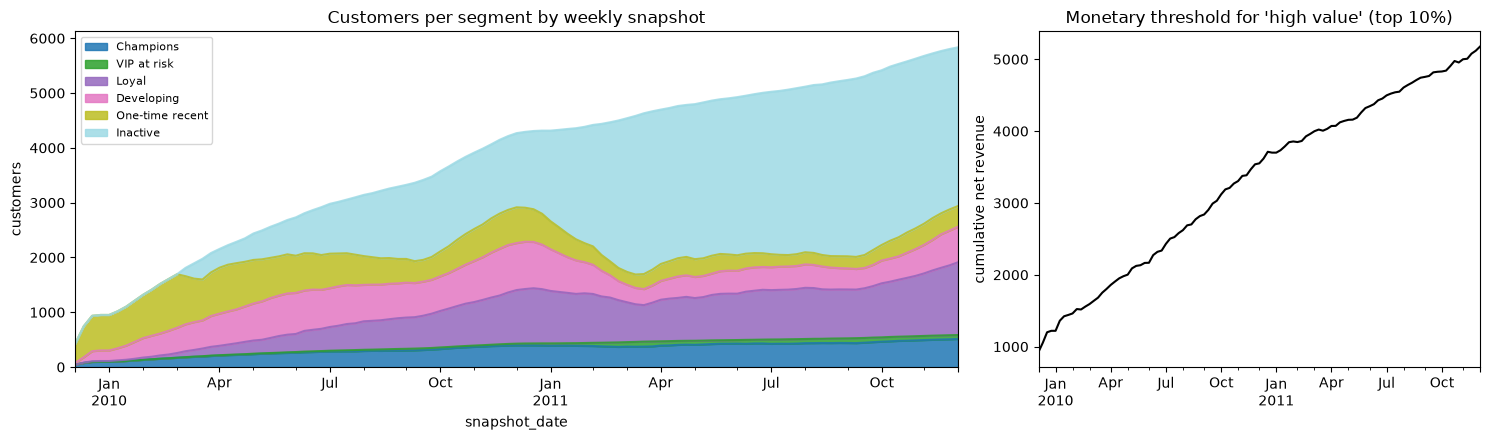

segment,Champions,VIP at risk,Loyal,Developing,One-time recent,Cooling,Lapsed,Dormant
snapshot_date,,,,,,,,
2009-12-07,43,0,2,31,349,0,0,0
2010-02-15,152,0,60,400,905,0,0,0
2010-07-05,285,13,433,709,629,699,211,0
2010-12-06,396,31,978,858,652,579,747,28
2011-06-20,431,67,895,427,260,598,1650,652
2011-12-05,513,71,1328,649,377,556,791,1550


In [13]:
seg_counts = weekly.groupby(["snapshot_date", "segment"], observed=False).size().unstack()

# Chart only: Cooling + Lapsed + Dormant merged into "Inactive"; the table below keeps all 8 segments
seg_plot = seg_counts[SEGMENTS[:5]].assign(Inactive=seg_counts[SEGMENTS[5:]].sum(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
seg_plot.plot.area(ax=axes[0], colormap="tab20", alpha=.85)
axes[0].set_ylabel("customers"); axes[0].set_title("Customers per segment by weekly snapshot")
axes[0].legend(loc="upper left", fontsize=8)
pd.Series(m_high_by_week).plot(ax=axes[1], color="black")
axes[1].set_title("Monetary threshold for 'high value' (top 10%)"); axes[1].set_ylabel("cumulative net revenue")
plt.tight_layout(); plt.show()
seg_counts.iloc[[0, 10, 30, 52, 80, -1]]

**Nhận xét biểu đồ:**

| # | Phát hiện | Bằng chứng | Ý nghĩa |
|---|---|---|---|
| 1 | Tổng số khách chỉ tăng, không giảm | 4,269 khách (2010-12-06) lên 5,835 (2011-12-05) | Khách đã mua thì ở lại bảng mãi mãi. Chiều cao tổng là số khách đã từng mua, không phải số khách đang hoạt động |
| 2 | Dormant và Lapsed phình ra theo thời gian | Dormant: 28 (2010-12-06), 590 (2011-06-06), 1,550 (2011-12-05), tức 27% tổng. Lapsed: 747, 1,650, 791 | Đây là lịch sử cộng dồn, không phải dấu hiệu tình hình xấu đi. Khó so Dormant của hai thời điểm khác nhau |
| 3 | Cooling tăng vọt sau mùa Q4 rồi xẹp | Từ 579 (2010-12-06) lên đỉnh 1,679 (2011-03-14), rồi còn 646 (2011-06-06) | Khách mua trong mùa cao điểm nguội dần qua mốc 90 ngày, rồi qua 180 và 365 ngày và chuyển hẳn sang Lapsed, Dormant |
| 4 | One-time recent và Developing teo lại sau Q4 | One-time recent từ 652 xuống 244 (2011-03-14); Developing từ 858 xuống 299 | Khách mới của mùa Q4 không quay lại sau 90 ngày |
| 5 | Champions và Loyal tăng đều | Champions từ 396 lên 513; Loyal từ 978 lên 1,328 (2010-12-06 → 2011-12-05) | Nhóm khách giá trị nhất ít chịu ảnh hưởng mùa vụ |
| 6 | VIP at risk nhỏ nhưng dao động theo mùa | 31 (2010-12-06), đỉnh 88 (2011-03-14), 71 (2011-12-05) | Khách giá trị cao vắng quá 90 ngày sau mùa cao điểm, một phần quay lại Champions |
| 7 | Ngưỡng M cao tăng gần tuyến tính | Từ khoảng 1,000 lên khoảng 5,200 | M cộng dồn chỉ tăng nên phải tính lại ngưỡng mỗi tuần |

### 9.2 Quỹ đạo nhóm của từng khách
Mỗi dòng là một khách, mỗi cột là một tuần. Ô trống nghĩa là khách chưa từng mua tính đến tuần đó.

In [14]:
wide = weekly.pivot(index="CustomerID", columns="snapshot_date", values="segment")
wide.columns = [c.strftime("%Y-%m-%d") for c in wide.columns]
wide.iloc[:5, -8:]

,2011-10-17,2011-10-24,2011-10-31,2011-11-07,2011-11-14,2011-11-21,2011-11-28,2011-12-05
CustomerID,,,,,,,,
12346,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed
12347,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal
12348,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal
12349,Lapsed,Lapsed,Dormant,Dormant,Dormant,Dormant,Developing,Developing
12350,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed


### 9.3 Chuyển nhóm giữa hai tuần liền kề: các sự kiện quan trọng
Chỉ tính khách có mặt ở cả hai tuần. Mỗi dòng là một sự kiện chuyển nhóm. Cooling, Lapsed, Dormant gộp thành **Inactive**.

* `customer_weeks_in_from`: số lượt (khách, tuần) mà khách đang ở nhóm xuất phát. Đây là mẫu số.
* `transitions`: số lượt khách sang nhóm đích ở tuần kế tiếp.
* `weekly_rate_pct`: `transitions` / `customer_weeks_in_from` × 100, tức xác suất chuyển nhóm trong **một tuần**, tính theo %.

In [15]:
trans = []
for a, b in zip(wide.columns[:-1], wide.columns[1:]):
    pair = wide[[a, b]].dropna().astype(str)
    trans.append(pd.DataFrame({"from_segment": pair[a].values, "to_segment": pair[b].values}))
trans = pd.concat(trans, ignore_index=True)

# Cooling, Lapsed and Dormant are merged into "Inactive" (same grouping as the charts above)
trans = trans.replace({s: "Inactive" for s in SEGMENTS[5:]})

# Only the events that matter for retention; one row per (from, to) pair
EVENTS = [
    ("Loyal", "Champions", "Loyal lên Champions"),
    ("Champions", "VIP at risk", "Champions trượt xuống VIP at risk"),
    ("Champions", "Inactive", "Champions rơi thẳng xuống Inactive"),
    ("VIP at risk", "Champions", "VIP at risk quay lại Champions"),
    ("VIP at risk", "Inactive", "VIP at risk rơi xuống Inactive"),
]
at_risk = trans["from_segment"].value_counts()
events = pd.DataFrame([{
    "event": label, "from_segment": f, "to_segment": t,
    "customer_weeks_in_from": int(at_risk.get(f, 0)),
    "transitions": int(((trans["from_segment"] == f) & (trans["to_segment"] == t)).sum()),
} for f, t, label in EVENTS])
events["weekly_rate_pct"] = (events["transitions"] / events["customer_weeks_in_from"] * 100).round(2)
events

,event,from_segment,to_segment,customer_weeks_in_from,transitions,weekly_rate_pct
0,Loyal lên Champions,Loyal,Champions,66034,565,0.86
1,Champions trượt xuống VIP at risk,Champions,VIP at risk,34602,431,1.25
2,Champions rơi thẳng xuống Inactive,Champions,Inactive,34602,7,0.02
3,VIP at risk quay lại Champions,VIP at risk,Champions,4330,291,6.72
4,VIP at risk rơi xuống Inactive,VIP at risk,Inactive,4330,69,1.59


# Lưu kết quả

* `customer_rfm.csv`: một dòng mỗi khách (phần A), gồm các đặc trưng RFM và nhóm.
* `segment_profile.csv`: hồ sơ nhóm (phần A).
* `weekly_rfm.csv`: một dòng mỗi (khách, tuần): R, F, M đến mốc đó, F và M của riêng tuần đó, và nhóm (phần B).
* `weekly_segment_wide.csv`: mỗi khách một dòng, mỗi tuần một cột nhóm.

In [16]:
rfm.to_csv("customer_rfm.csv", index=False)
profile.to_csv("segment_profile.csv")
weekly.to_csv("weekly_rfm.csv", index=False)
wide.to_csv("weekly_segment_wide.csv")
print("Saved customer_rfm.csv, segment_profile.csv, weekly_rfm.csv, weekly_segment_wide.csv")

Saved customer_rfm.csv, segment_profile.csv, weekly_rfm.csv, weekly_segment_wide.csv
